# ORBITGUARD Stage 2: Exploratory Data Analysis

This notebook describes the downloaded OPSSAT-AD data. It checks the segment-level feature table and raw telemetry, creates presentation-ready figures under `reports/figures/`, and reports observations calculated from the files. It does **not** change the source data, select features, preprocess values, or train a model.

Run the cells from top to bottom in VS Code or Google Colab. The original Stage 1 downloads must be available under `data/raw/`.

## 1. Set up paths and plotting tools

We use Pandas and NumPy to inspect the tables and calculate summaries, and Matplotlib and Seaborn to make the charts. The path setup works if this notebook is started from the project root or from its `notebooks` folder. Figures are saved separately from the original dataset.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import ENGINEERED_FEATURE_COLUMNS

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print(f"Project folder: {PROJECT_ROOT}")
print(f"Figures will be saved to: {FIGURES_DIR}")

Project folder: C:\Users\HP\OneDrive\Desktop\orbit gaurd
Figures will be saved to: C:\Users\HP\OneDrive\Desktop\orbit gaurd\reports\figures


## 2. Load the original files and verify their dimensions

`dataset.csv` has one record per labeled telemetry segment. `segments.csv` contains the timestamped raw signal samples. The cells below only read the files; they do not overwrite or alter them. A missing file produces a clear instruction to complete Stage 1 first.

In [2]:
feature_path = RAW_DATA_DIR / "dataset.csv"
raw_path = RAW_DATA_DIR / "segments.csv"
missing_files = [str(path) for path in (feature_path, raw_path) if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Stage 1 data files are missing: " + ", ".join(missing_files)
        + ". Run notebooks/01_data_collection.ipynb to download them."
    )

segments = pd.read_csv(feature_path)
raw_telemetry = pd.read_csv(raw_path)

print(f"Feature dataset: {segments.shape[0]:,} rows × {segments.shape[1]} columns")
print(f"Raw telemetry:   {raw_telemetry.shape[0]:,} rows × {raw_telemetry.shape[1]} columns")
print(f"Unique telemetry segments in raw file: {raw_telemetry['segment'].nunique():,}")
print("\nFeature dataset preview:")
display(segments.head())

Feature dataset: 2,123 rows × 23 columns
Raw telemetry:   303,493 rows × 8 columns
Unique telemetry segments in raw file: 2,123

Feature dataset preview:


,segment,anomaly,train,channel,sampling,duration,len,mean,var,std,kurtosis,skew,n_peaks,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
0,1,1,1,CADC0872,1,279,280,8.533143e-07,3.494283e-10,0.000019,0.631117,0.552052,4,3,2,4,6,1.271176e-10,2.960666e-10,309,280,1.252431e-12,1.247958e-12
1,2,1,1,CADC0872,1,476,477,-3.639396e-06,6.476485e-10,0.000025,-1.243611,0.425632,1,1,1,5,8,1.489383e-12,3.004752e-12,644,477,1.360606e-12,1.357754e-12
2,3,1,1,CADC0872,1,594,595,1.170788e-05,5.592877e-10,0.000024,-0.284593,-0.826187,3,2,2,2,3,4.112280e-12,1.029918e-11,772,595,9.415618e-13,9.399794e-13
3,4,1,1,CADC0872,1,271,272,8.486808e-07,5.466024e-10,0.000023,-0.887088,-0.138498,2,2,2,3,6,2.475760e-11,6.240985e-11,339,272,2.016983e-12,2.009568e-12
4,5,0,0,CADC0872,1,255,257,1.058485e-05,5.279023e-10,0.000023,-1.484393,-0.060155,1,1,1,78,87,5.547101e-13,7.035422e-13,357,257,2.070205e-12,2.054094e-12


### Column names and data types

This inventory uses the column names and data types inferred from the downloaded CSVs. The feature table includes numeric measurements as well as `segment` (an identifier), `channel` and `sampling` (metadata), `anomaly` (target), and `train` (the supplied split).

In [3]:
print("Feature dataset columns and inferred dtypes:")
display(pd.DataFrame({"column": segments.columns, "dtype": segments.dtypes.astype(str).values}))

print("Raw telemetry columns and inferred dtypes:")
display(pd.DataFrame({"column": raw_telemetry.columns, "dtype": raw_telemetry.dtypes.astype(str).values}))

Feature dataset columns and inferred dtypes:


,column,dtype
0,segment,int64
1,anomaly,int64
2,train,int64
3,channel,str
4,sampling,int64
5,duration,int64
6,len,int64
7,mean,float64
8,var,float64
9,std,float64


Raw telemetry columns and inferred dtypes:


,column,dtype
0,channel,str
1,timestamp,str
2,value,float64
3,label,str
4,sampling,int64
5,anomaly,int64
6,segment,int64
7,train,int64


## 3. Missing values, duplicate records, and statistical summary

Missing values and exact duplicate rows are counted separately for both source tables. Duplicate segment identifiers are also checked in the segment-level table. The descriptive statistics are calculated from the feature table as stored; unusual values are not removed or corrected.

In [4]:
quality_summary = pd.DataFrame(
    {
        "missing_cells": [int(segments.isna().sum().sum()), int(raw_telemetry.isna().sum().sum())],
        "duplicate_rows": [int(segments.duplicated().sum()), int(raw_telemetry.duplicated().sum())],
        "rows": [len(segments), len(raw_telemetry)],
    },
    index=["dataset.csv", "segments.csv"],
)
print("Data quality checks:")
display(quality_summary)
print(f"Repeated segment IDs in dataset.csv: {segments['segment'].duplicated().sum():,}")

print("Descriptive statistics for all columns in dataset.csv:")
display(segments.describe(include="all").T)

Data quality checks:


,missing_cells,duplicate_rows,rows
dataset.csv,0,0,2123
segments.csv,0,0,303493


Repeated segment IDs in dataset.csv: 0
Descriptive statistics for all columns in dataset.csv:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
segment,2123.0,NaN,NaN,NaN,1062.0,613.001631,1.0,531.5,1062.0,1592.5,2123.0
anomaly,2123.0,NaN,NaN,NaN,0.204428,0.403378,0.0,0.0,0.0,0.0,1.0
train,2123.0,NaN,NaN,NaN,0.750824,0.432638,0.0,1.0,1.0,1.0,1.0
channel,2123,9,CADC0873,593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sampling,2123.0,NaN,NaN,NaN,3.505888,1.935418,1.0,1.0,5.0,5.0,5.0
duration,2123.0,NaN,NaN,NaN,267.952426,169.093207,35.0,175.0,225.0,336.0,1335.0
len,2123.0,NaN,NaN,NaN,142.954781,152.329786,8.0,40.0,70.0,201.0,1040.0
mean,2123.0,NaN,NaN,NaN,0.110968,0.196316,-0.000038,-0.000001,0.000005,0.205171,1.118632
var,2123.0,NaN,NaN,NaN,0.030659,0.054912,0.0,0.0,0.0,0.037388,0.27248
std,2123.0,NaN,NaN,NaN,0.096226,0.146319,0.000004,0.000017,0.000025,0.193361,0.521996


## 4. Class balance and supplied train/test split

The first count plot shows how many segments are normal (`anomaly=0`) and anomalous (`anomaly=1`). The second plot compares both target classes within the already-provided train and test splits (`train=1` is training; `train=0` is testing). Counts and percentages are reported to make class imbalance clear. These plots describe the supplied split; they do not create a new one.

Segment class counts:


,count,percent
anomaly,,
0,1689,79.56
1,434,20.44


Normal-to-anomaly count ratio: 3.89:1


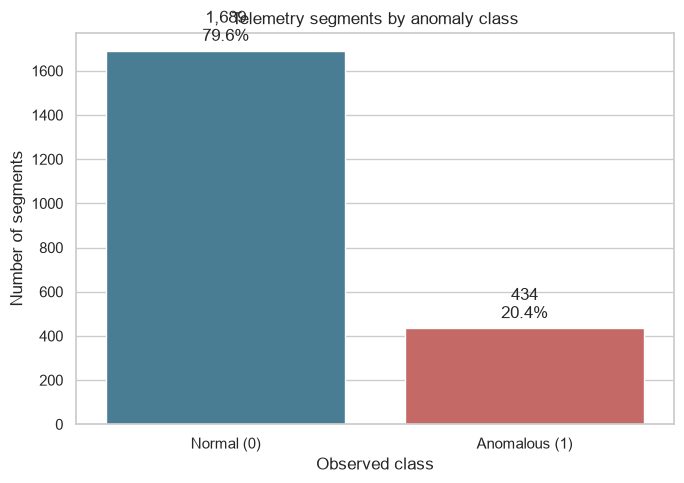

In [5]:
required_columns = {"anomaly", "train"}
missing_required = required_columns.difference(segments.columns)
if missing_required:
    raise ValueError(f"Feature dataset is missing required columns: {sorted(missing_required)}")
if not set(segments["anomaly"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected the documented binary anomaly target values 0 and 1.")
if not set(segments["train"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected the documented train split values 0 and 1.")

class_names = {0: "Normal (0)", 1: "Anomalous (1)"}
split_names = {0: "Test (train=0)", 1: "Train (train=1)"}
plot_data = segments.assign(
    class_name=segments["anomaly"].map(class_names),
    split_name=segments["train"].map(split_names),
)
class_order = [class_names[0], class_names[1]]
split_order = [split_names[0], split_names[1]]
class_palette = {class_names[0]: "#3B82A0", class_names[1]: "#D45A55"}

class_counts = segments["anomaly"].value_counts().sort_index()
class_percentages = segments["anomaly"].value_counts(normalize=True).sort_index() * 100
normal_count = int(class_counts.get(0, 0))
anomaly_count = int(class_counts.get(1, 0))
imbalance_ratio = normal_count / anomaly_count if anomaly_count else np.nan
print("Segment class counts:")
display(pd.DataFrame({"count": class_counts, "percent": class_percentages.round(2)}))
print(f"Normal-to-anomaly count ratio: {imbalance_ratio:.2f}:1")

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(
    data=plot_data,
    x="class_name",
    hue="class_name",
    order=class_order,
    hue_order=class_order,
    palette=class_palette,
    legend=False,
    ax=ax,
)
ax.set(title="Telemetry segments by anomaly class", xlabel="Observed class", ylabel="Number of segments")
for patch, class_name in zip(ax.patches, class_order):
    count = int(patch.get_height())
    percent = class_percentages.loc[0 if class_name == class_names[0] else 1]
    ax.annotate(f"{count:,}\n{percent:.1f}%", (patch.get_x() + patch.get_width() / 2, count),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**How to read this graph:** Each bar is a segment count, and its annotation also shows the share of the full dataset. A visibly shorter anomalous bar indicates class imbalance: the dataset has fewer anomalous examples than normal examples. This matters when interpreting later model results, but this notebook does not rebalance the data.

Observed split-by-class counts:


,Normal (0),Anomalous (1)
Test (train=0),416,113
Train (train=1),1273,321


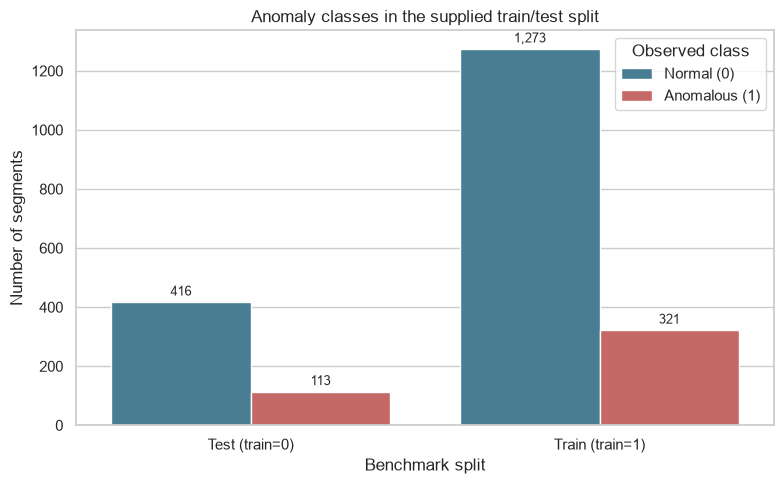

In [6]:
split_class_counts = pd.crosstab(segments["train"], segments["anomaly"]).reindex(
    index=[0, 1], columns=[0, 1], fill_value=0
)
split_class_counts.index = [split_names[value] for value in split_class_counts.index]
split_class_counts.columns = [class_names[value] for value in split_class_counts.columns]
print("Observed split-by-class counts:")
display(split_class_counts)

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=plot_data,
    x="split_name",
    hue="class_name",
    order=split_order,
    hue_order=class_order,
    palette=class_palette,
    ax=ax,
)
ax.set(title="Anomaly classes in the supplied train/test split", xlabel="Benchmark split", ylabel="Number of segments")
ax.legend(title="Observed class")
for patch in ax.patches:
    count = int(patch.get_height())
    if count:
        ax.annotate(f"{count:,}", (patch.get_x() + patch.get_width() / 2, count),
                    ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "train_test_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**How to read this graph:** The bars show the actual number of normal and anomalous segments in each supplied split. Compare the class mix within the train and test groups. This checks how the benchmark divided its data; it does not imply the data should be randomly split again.

## 5. Engineered feature distributions

The histograms use the 18 benchmark feature columns documented in Stage 1. Each panel overlays the normal and anomalous segment values for one feature, with a separate horizontal scale per panel. The plotted values are original values: no scaling, clipping, or outlier removal is applied.

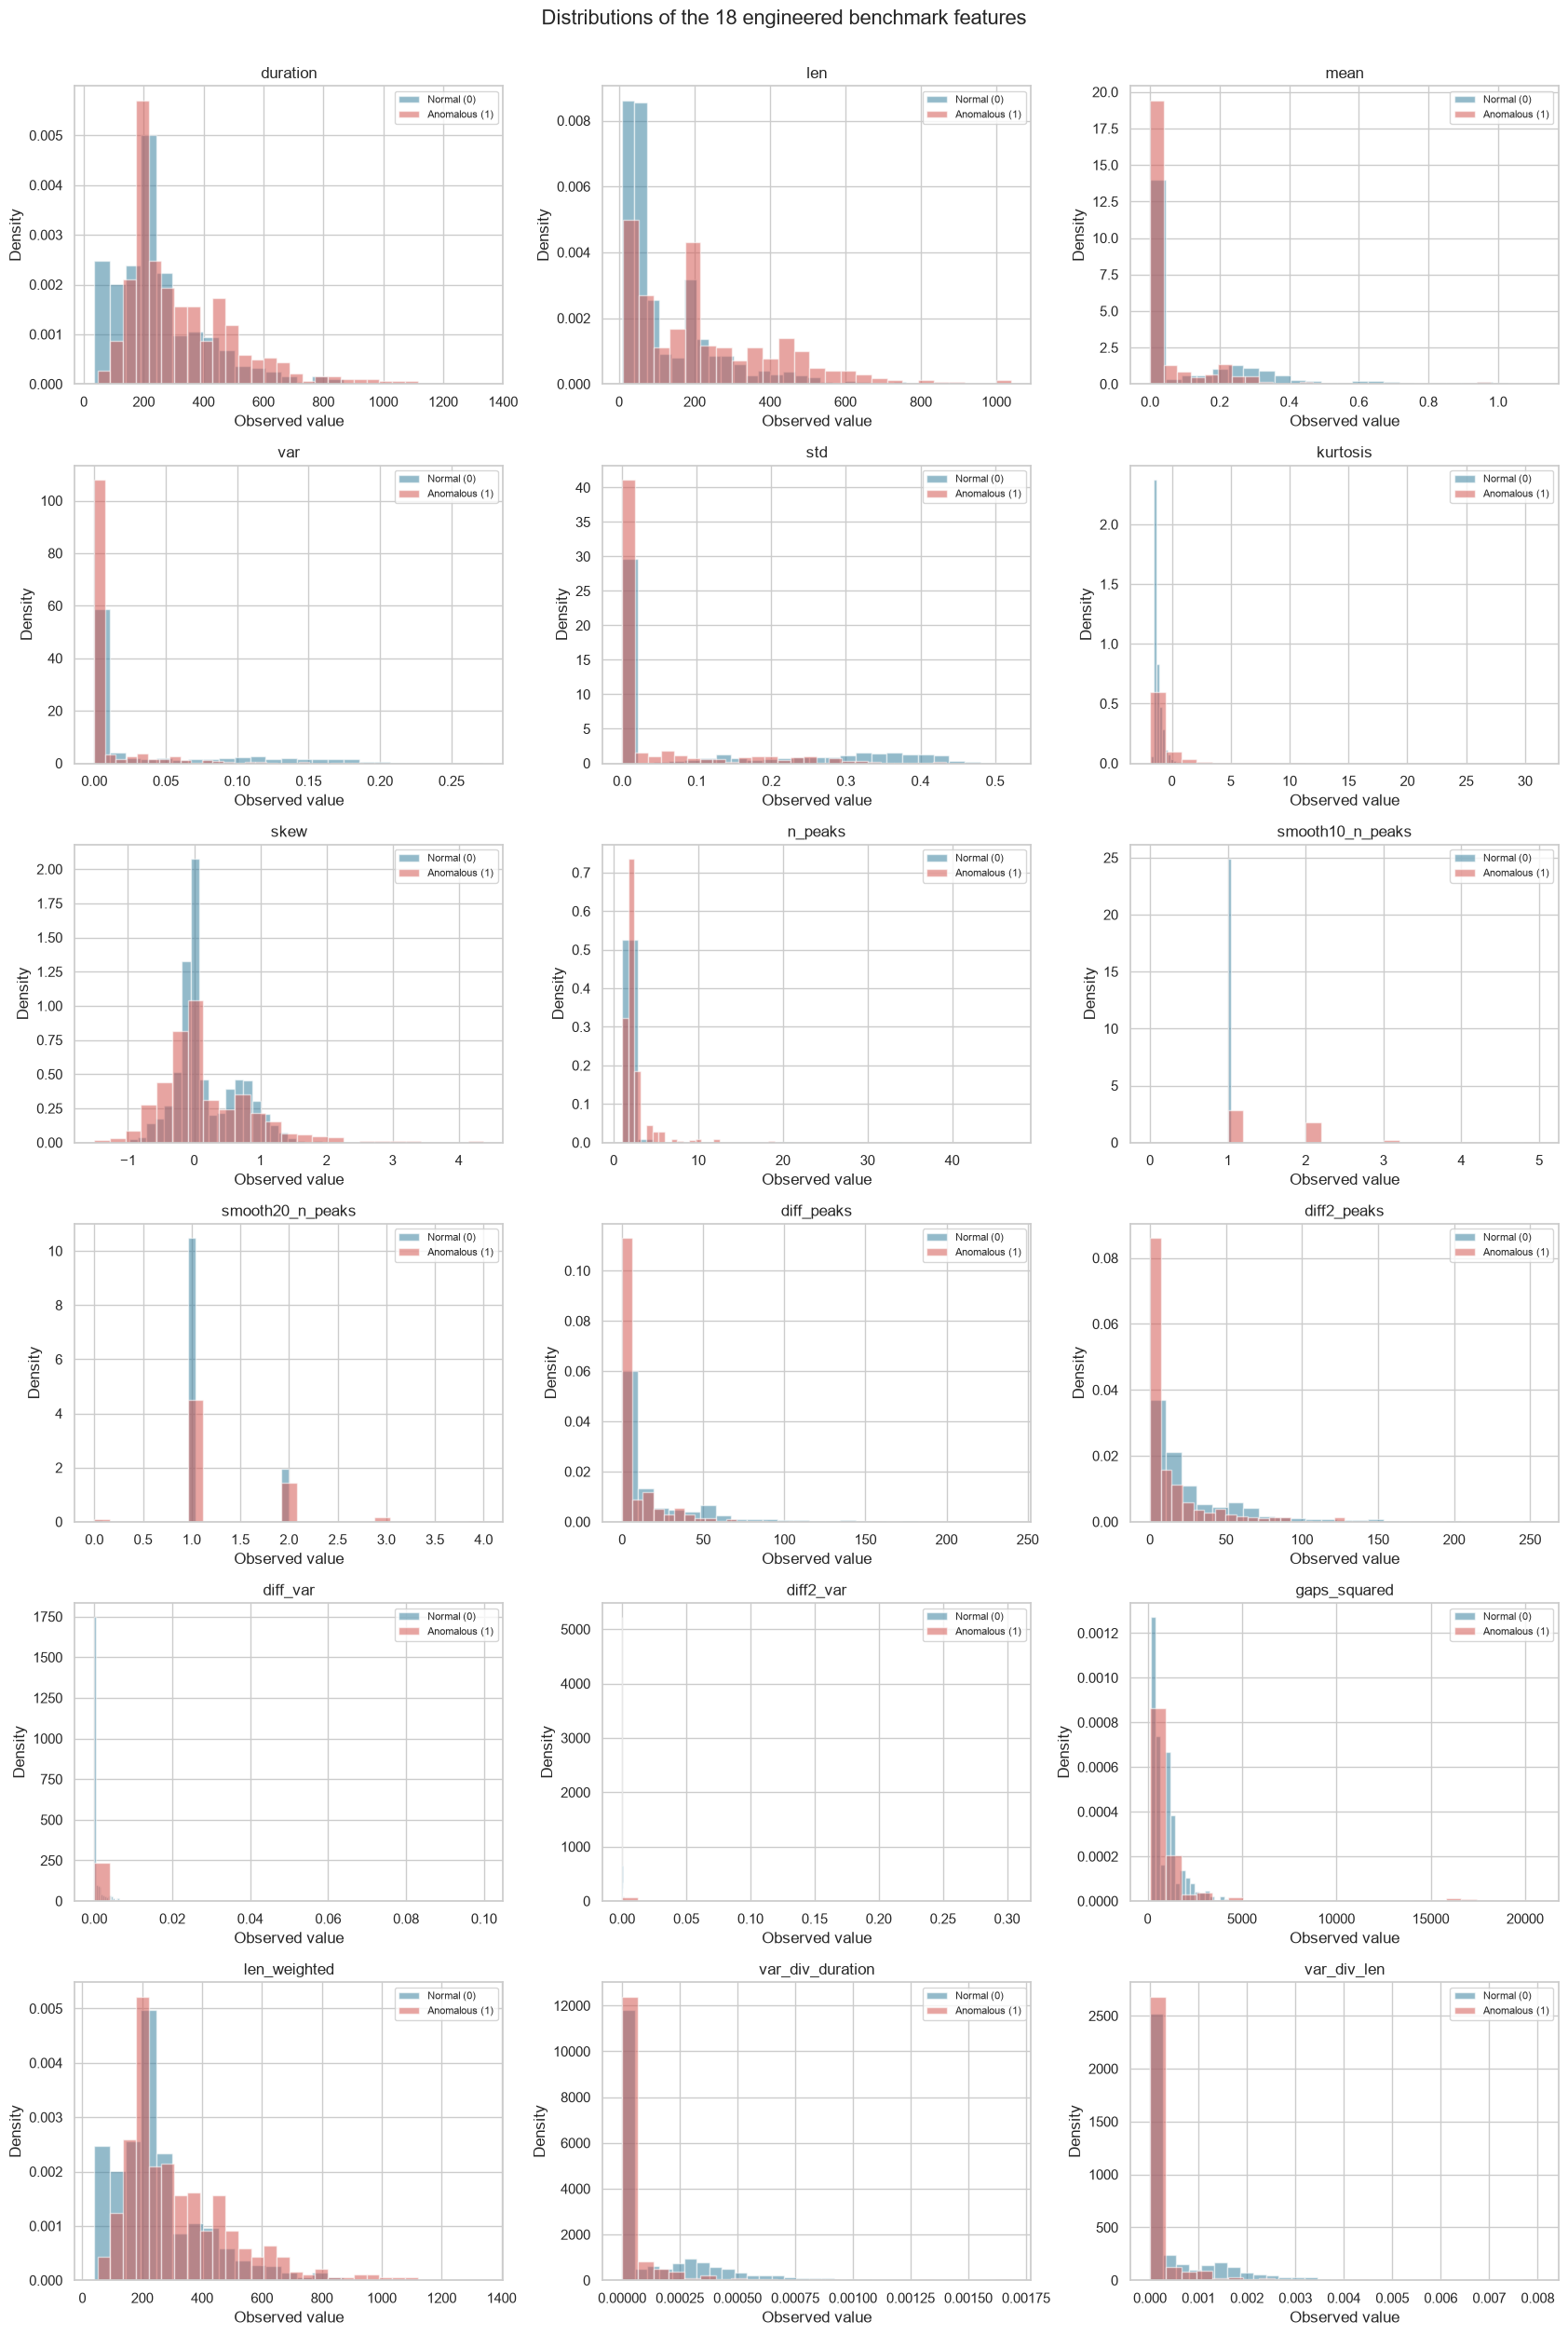

In [7]:
missing_features = [name for name in ENGINEERED_FEATURE_COLUMNS if name not in segments.columns]
if missing_features:
    raise ValueError(f"Feature dataset is missing benchmark feature columns: {missing_features}")

fig, axes = plt.subplots(6, 3, figsize=(17, 25))
for feature_name, ax in zip(ENGINEERED_FEATURE_COLUMNS, axes.flat):
    for class_value, class_name in class_names.items():
        values = segments.loc[segments["anomaly"].eq(class_value), feature_name].dropna()
        ax.hist(values, bins=25, alpha=0.55, density=True, label=class_name,
                color=class_palette[class_name])
    ax.set_title(feature_name)
    ax.set_xlabel("Observed value")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
fig.suptitle("Distributions of the 18 engineered benchmark features", y=1.002, fontsize=16)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_histograms.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**How to read these graphs:** Each histogram shows where a feature's values occur for each class. Overlap means the feature values are not unique to one class by themselves; separated shapes suggest a difference worth studying later. Different features have different units and ranges, so compare classes within a panel, not heights or x-axis scales across panels.

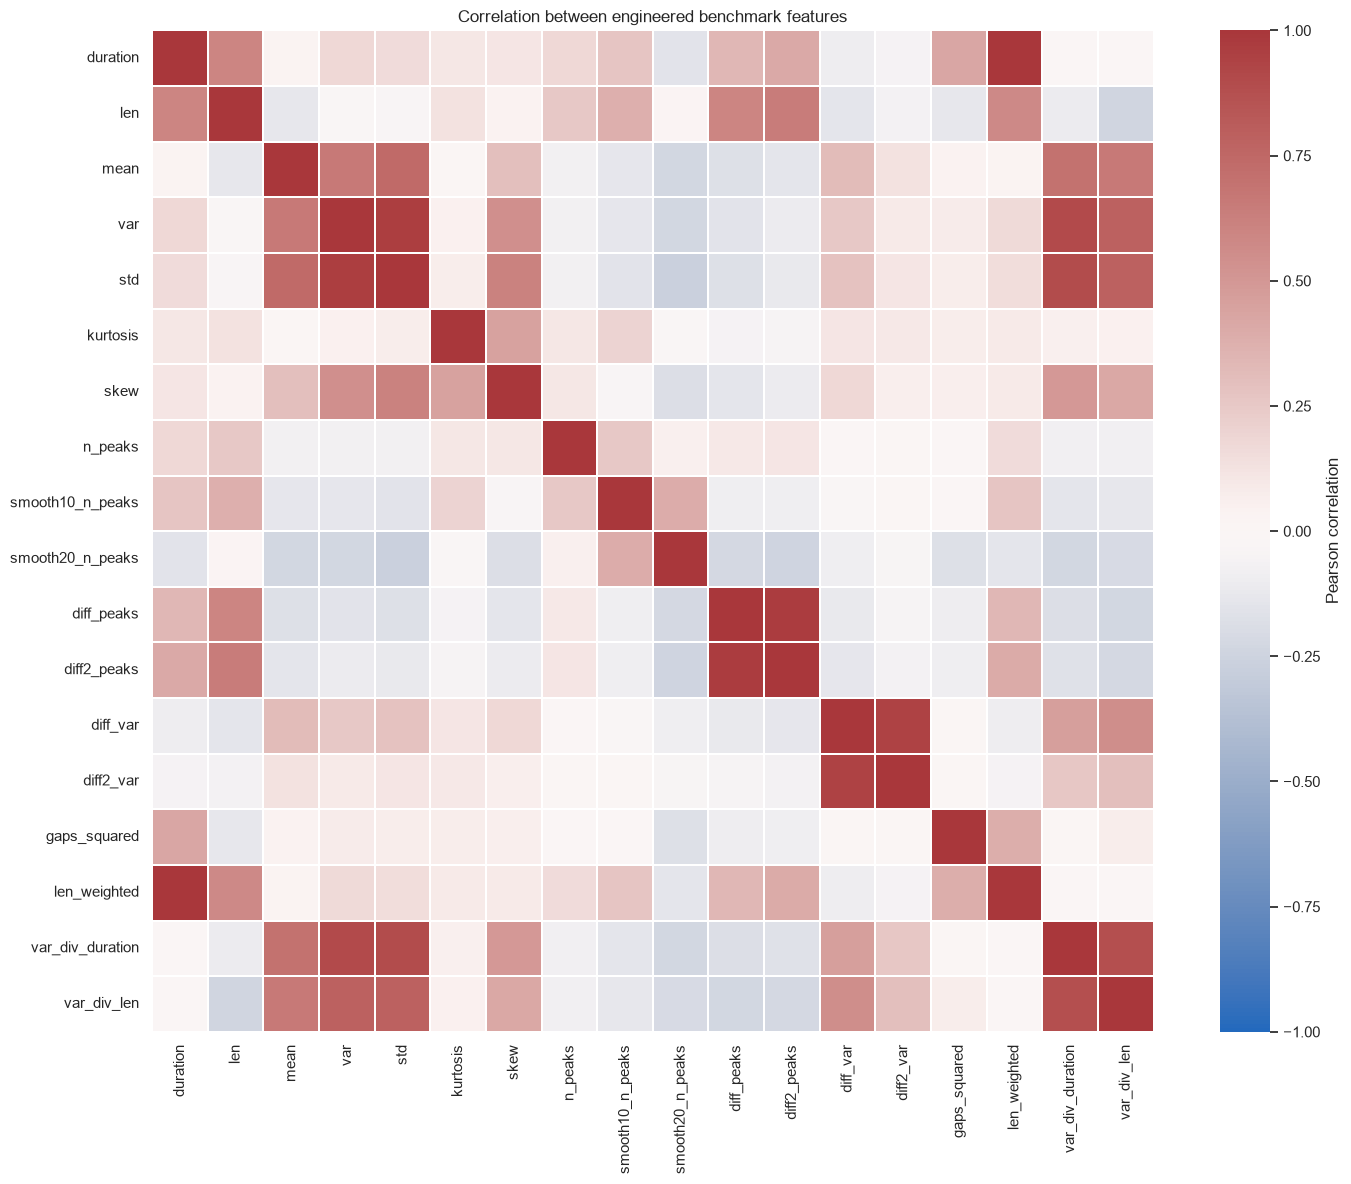

In [8]:
feature_values = segments.loc[:, list(ENGINEERED_FEATURE_COLUMNS)]
correlation = feature_values.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.25, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set(title="Correlation between engineered benchmark features")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_correlation_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**How to read this graph:** A value near `1` means two features tend to increase together, a value near `-1` means one tends to decrease as the other increases, and a value near `0` indicates weaker linear association. Correlation is descriptive and does not establish cause or determine which features should be retained.

## 6. Compare feature values by class and inspect potential outliers

Each box plot compares normal and anomalous records for one engineered feature. Because feature units and ranges differ, each panel has its own y-axis. The outlier table applies the conventional 1.5×IQR rule separately to each feature across all segments. This is a descriptive flag only: it does not mean a telemetry record is erroneous, and no records are removed.

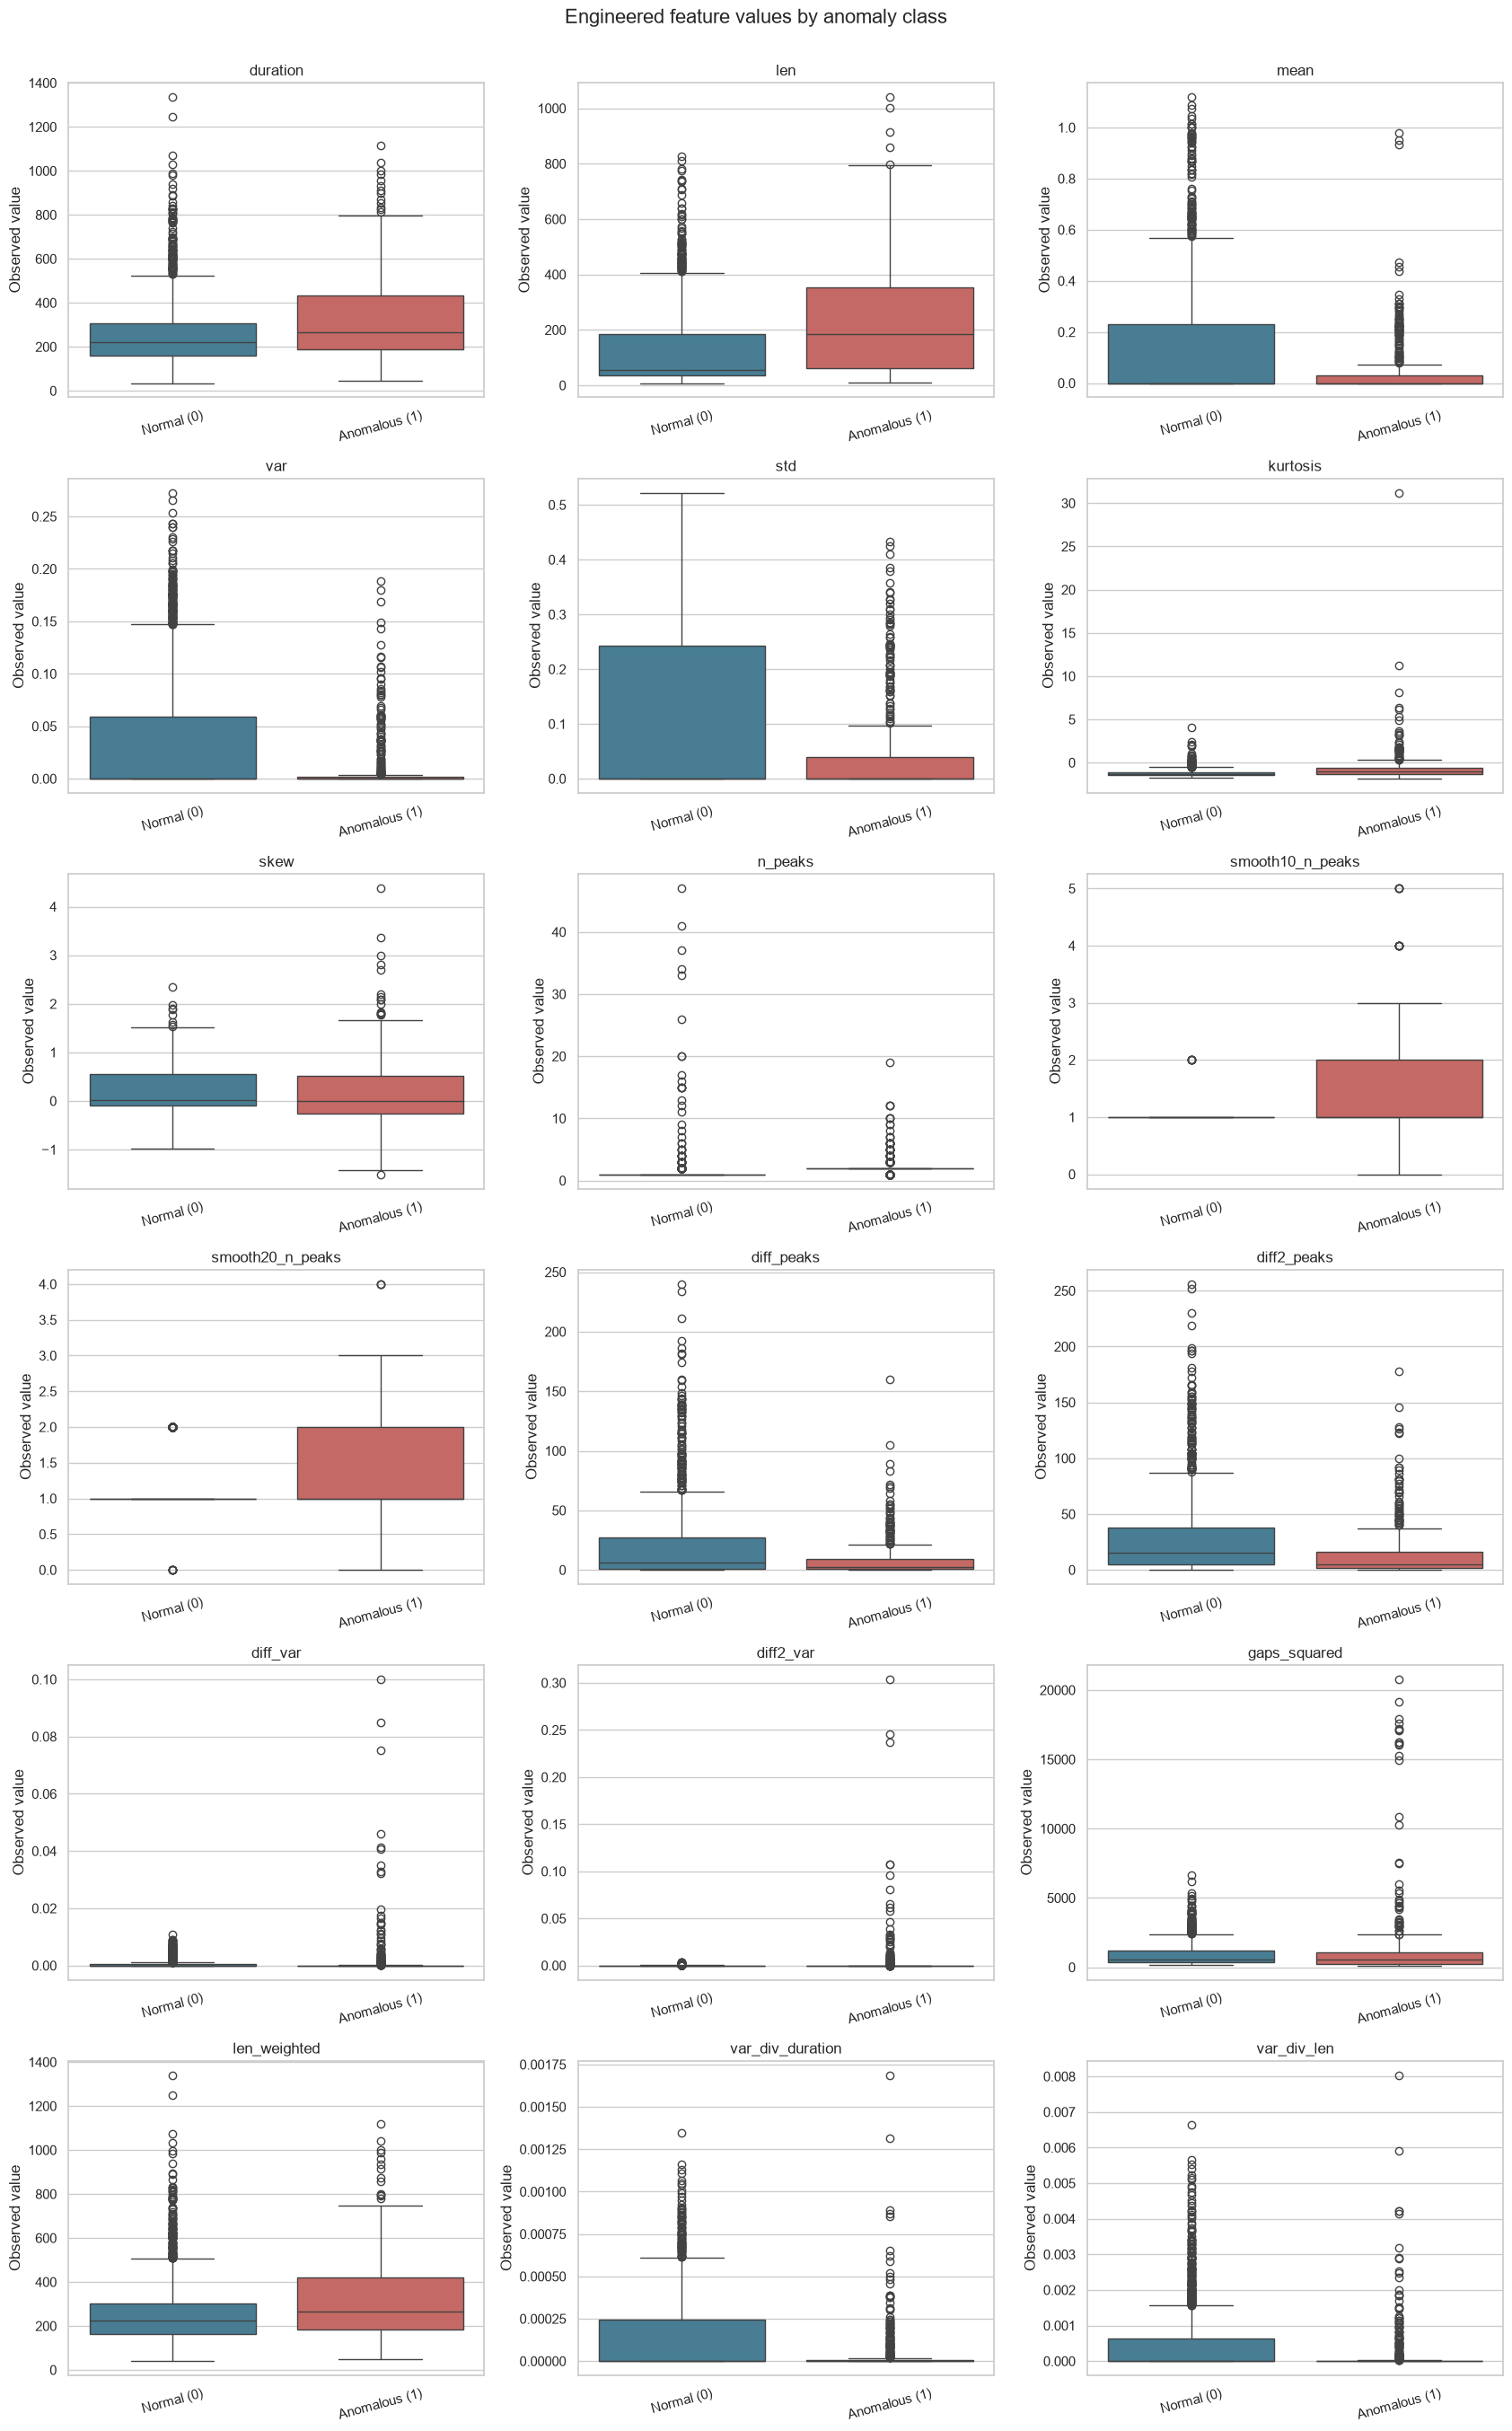

In [9]:
fig, axes = plt.subplots(6, 3, figsize=(17, 27))
for feature_name, ax in zip(ENGINEERED_FEATURE_COLUMNS, axes.flat):
    sns.boxplot(data=plot_data, x="class_name", y=feature_name, order=class_order,
                hue="class_name", hue_order=class_order, palette=class_palette,
                legend=False, showfliers=True, ax=ax)
    ax.set_title(feature_name)
    ax.set_xlabel("")
    ax.set_ylabel("Observed value")
    ax.tick_params(axis="x", labelrotation=15)
fig.suptitle("Engineered feature values by anomaly class", y=1.002, fontsize=16)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_boxplots_by_class.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**How to read these graphs:** The line inside each box is the median; the box spans the middle half of observed values. Points beyond the whiskers are plotted as potential outliers. Compare the two class boxes within each feature panel to see whether their centers and spreads differ. A plotted outlier is not automatically a bad value.

Potential outlier counts by feature (1.5×IQR fences, computed feature by feature):


,potential_outlier_count,percent_of_segments
n_peaks,469,22.09
diff_var,443,20.87
smooth20_n_peaks,394,18.56
var,341,16.06
var_div_len,330,15.54
diff2_var,322,15.17
diff_peaks,236,11.12
smooth10_n_peaks,191,9.00
var_div_duration,169,7.96
diff2_peaks,155,7.30


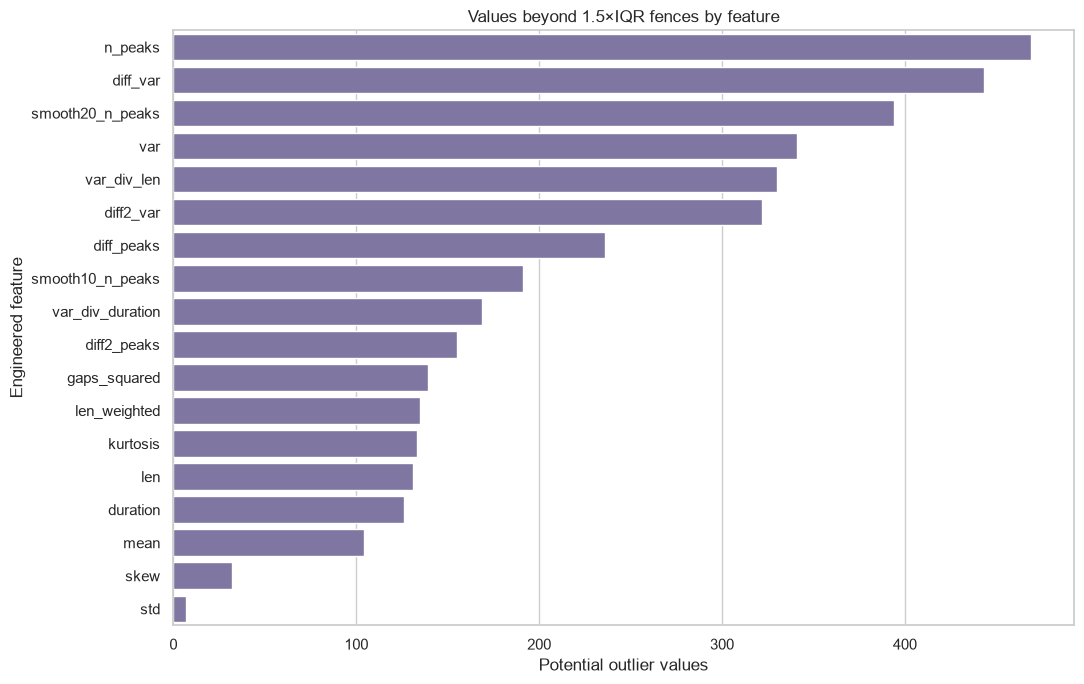

In [10]:
q1 = feature_values.quantile(0.25)
q3 = feature_values.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outlier_mask = feature_values.lt(lower_fence) | feature_values.gt(upper_fence)
outlier_summary = pd.DataFrame({
    "potential_outlier_count": outlier_mask.sum().astype(int),
    "percent_of_segments": (outlier_mask.mean() * 100).round(2),
}).sort_values("potential_outlier_count", ascending=False)
print("Potential outlier counts by feature (1.5×IQR fences, computed feature by feature):")
display(outlier_summary)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=outlier_summary.reset_index(names="feature"),
            x="potential_outlier_count", y="feature", color="#7B6FA8", ax=ax)
ax.set(title="Values beyond 1.5×IQR fences by feature", xlabel="Potential outlier values", ylabel="Engineered feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "potential_outliers_by_feature.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

**How to read this graph:** A taller bar means more segment values for that feature fall beyond its IQR fences. Features naturally have different distributions, so these counts are not a ranking of data quality. The flags are retained as-is for later investigation.

## 7. Channel-wise anomaly counts and rates

The feature table contains a `channel` column, so channel-level summaries are supported. The table and chart show the number of segments and observed anomaly rate per channel. Rates are paired with counts because a rate from a channel with few segments is less stable than a rate supported by many records. Channel is metadata here, not an engineered model feature.

Observed channels: 9


,segment_count,anomalous_segments,anomaly_rate_percent
channel,,,
CADC0873,593,105,17.706577
CADC0872,546,131,23.992674
CADC0888,252,60,23.809524
CADC0892,211,34,16.113744
CADC0874,194,69,35.567010
CADC0884,158,0,0.000000
CADC0894,144,21,14.583333
CADC0890,14,11,78.571429
CADC0886,11,3,27.272727


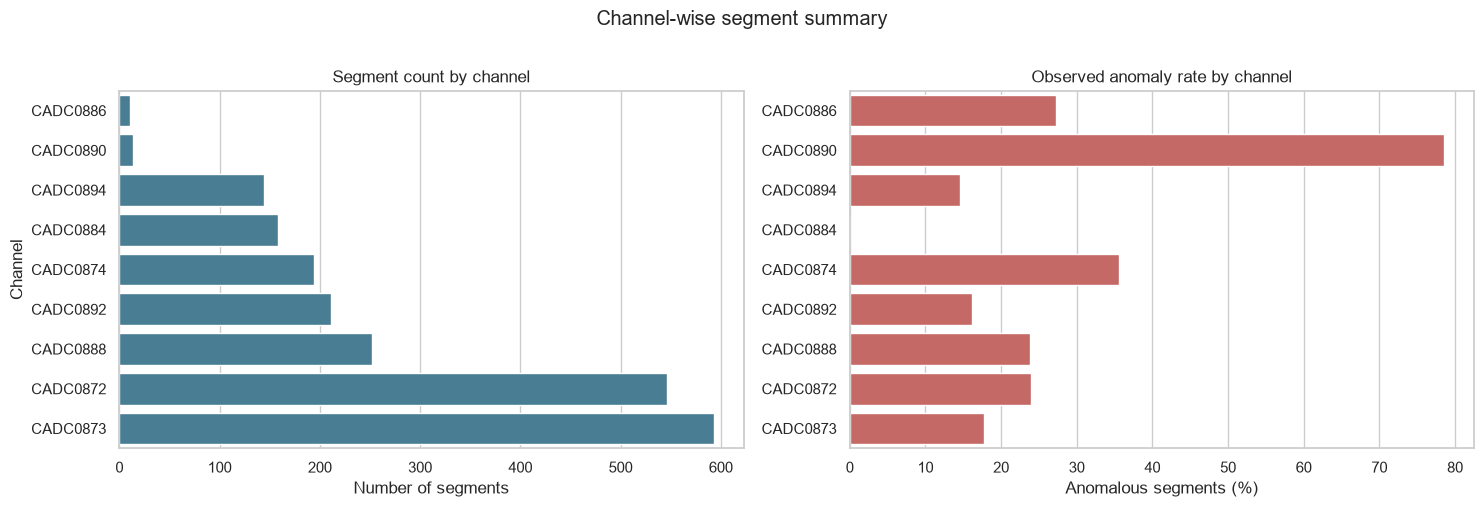

In [11]:
if "channel" not in segments.columns:
    print("Channel-wise analysis skipped: dataset.csv has no channel column.")
else:
    channel_summary = (
        segments.groupby("channel", dropna=False)
        .agg(segment_count=("segment", "size"), anomalous_segments=("anomaly", "sum"),
             anomaly_rate=("anomaly", "mean"))
        .sort_values("segment_count", ascending=False)
    )
    channel_summary["anomaly_rate_percent"] = channel_summary["anomaly_rate"] * 100
    print(f"Observed channels: {len(channel_summary)}")
    display(channel_summary.drop(columns="anomaly_rate"))

    channel_plot = channel_summary.sort_values("segment_count", ascending=True)
    fig, axes = plt.subplots(1, 2, figsize=(15, max(5, 0.55 * len(channel_plot))))
    sns.barplot(data=channel_plot.reset_index(), x="segment_count", y="channel",
                color="#3B82A0", ax=axes[0])
    axes[0].set(title="Segment count by channel", xlabel="Number of segments", ylabel="Channel")
    sns.barplot(data=channel_plot.reset_index(), x="anomaly_rate_percent", y="channel",
                color="#D45A55", ax=axes[1])
    axes[1].set(title="Observed anomaly rate by channel", xlabel="Anomalous segments (%)", ylabel="")
    fig.suptitle("Channel-wise segment summary", y=1.01)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "channel_anomaly_analysis.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

**How to read this graph:** The left panel shows how many labeled segments each channel contributes. The right panel shows the observed fraction labeled anomalous within that channel. Differences can reflect the composition of this dataset and should not be interpreted as causal or as a model result.

## 8. Example raw telemetry traces

`segments.csv` contains raw `timestamp`, `value`, `segment`, and `anomaly` fields, so a sample-level visualization is supported. For a concise plot, the code picks the lowest-numbered segment available in each class and plots its time-ordered samples. These are examples, not class averages or claims that the selected traces are representative. The source rows and labels are not changed.

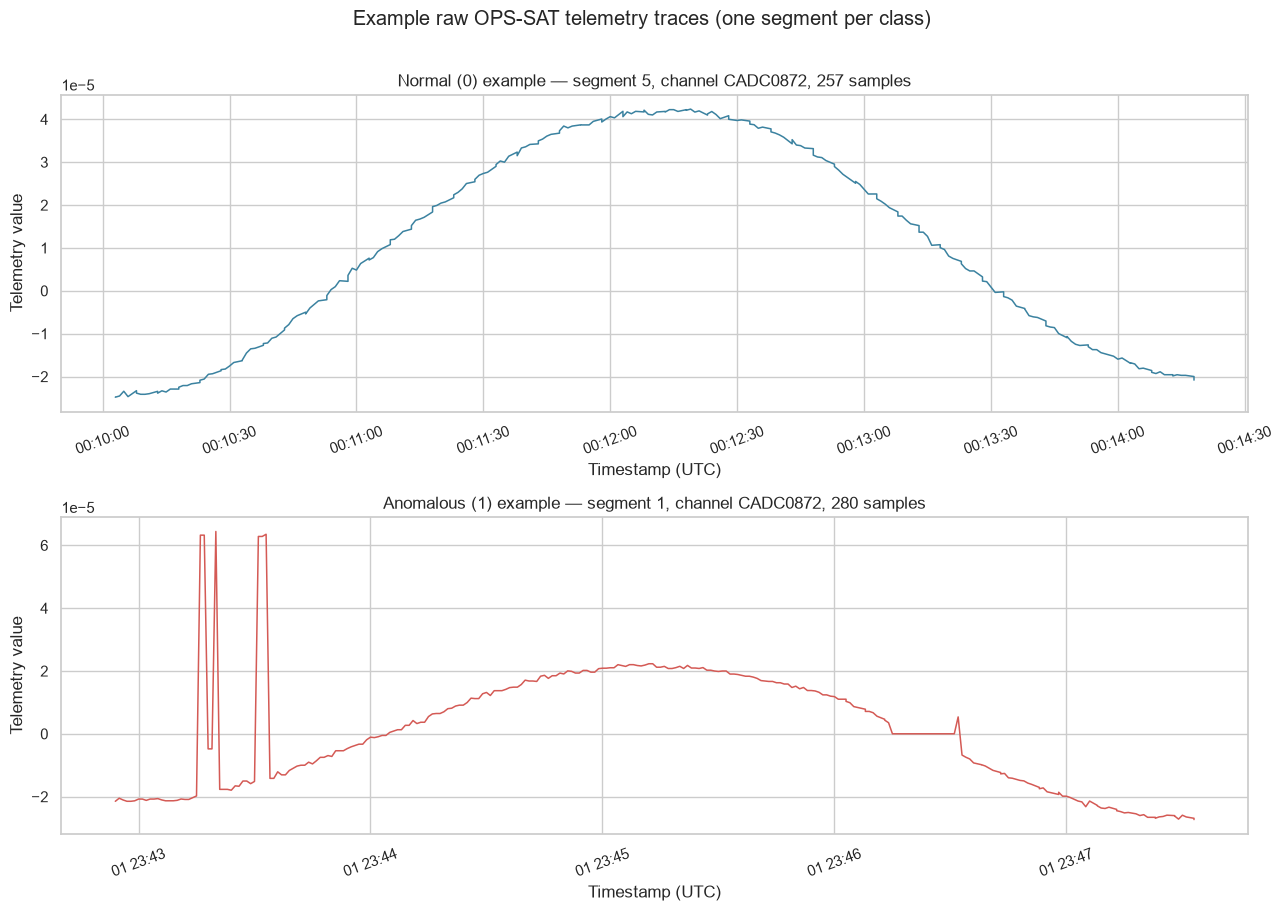

In [12]:
raw_columns = {"timestamp", "value", "segment", "anomaly"}
missing_raw_columns = raw_columns.difference(raw_telemetry.columns)
if missing_raw_columns:
    print(f"Raw telemetry line plots skipped; missing columns: {sorted(missing_raw_columns)}")
else:
    raw_for_plot = raw_telemetry.copy()
    raw_for_plot["timestamp"] = pd.to_datetime(raw_for_plot["timestamp"], utc=True, errors="coerce")
    if raw_for_plot["timestamp"].isna().any():
        raise ValueError("Some raw telemetry timestamps could not be parsed.")

    raw_segment_classes = raw_for_plot.groupby("segment")["anomaly"].nunique()
    if raw_segment_classes.gt(1).any():
        raise ValueError("A raw telemetry segment has inconsistent anomaly labels.")

    fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=False)
    for ax, class_value in zip(axes, [0, 1]):
        available_ids = raw_for_plot.loc[raw_for_plot["anomaly"].eq(class_value), "segment"]
        if available_ids.empty:
            ax.set_visible(False)
            continue
        selected_id = int(available_ids.min())
        trace = raw_for_plot.loc[raw_for_plot["segment"].eq(selected_id)].sort_values("timestamp")
        channel_name = trace["channel"].iloc[0] if "channel" in trace.columns else "unknown"
        class_name = class_names[class_value]
        ax.plot(trace["timestamp"], trace["value"], color=class_palette[class_name], linewidth=1.1)
        ax.set_title(f"{class_name} example — segment {selected_id}, channel {channel_name}, {len(trace):,} samples")
        ax.set_xlabel("Timestamp (UTC)")
        ax.set_ylabel("Telemetry value")
        ax.tick_params(axis="x", labelrotation=20)
    fig.suptitle("Example raw OPS-SAT telemetry traces (one segment per class)", y=1.01)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "raw_telemetry_class_examples.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

**How to read this graph:** Each line is the observed telemetry value over time for one segment, with the binary class and actual segment/channel printed in its title. The two traces are examples only; class-level conclusions should be based on the full dataset, not these two selected segments.

## 9. Data-backed findings for a project presentation

The statements below are calculated from the loaded files. They summarize dataset composition and quality; they do not claim predictive performance or causal relationships.

In [13]:
train_count = int(segments["train"].eq(1).sum())
test_count = int(segments["train"].eq(0).sum())
train_anomaly_rate = segments.loc[segments["train"].eq(1), "anomaly"].mean() * 100
test_anomaly_rate = segments.loc[segments["train"].eq(0), "anomaly"].mean() * 100
print(f"1. The feature dataset contains {len(segments):,} labeled segments and {len(segments.columns)} columns.")
print(f"2. There are {normal_count:,} normal ({class_percentages.loc[0]:.2f}%) and "
      f"{anomaly_count:,} anomalous ({class_percentages.loc[1]:.2f}%) segments.")
print(f"3. Normal segments outnumber anomalous segments by {imbalance_ratio:.2f} to 1; the classes are imbalanced.")
print(f"4. The supplied split contains {train_count:,} training and {test_count:,} test segments.")
print(f"5. The anomalous share is {train_anomaly_rate:.2f}% in training and {test_anomaly_rate:.2f}% in test.")
print(f"6. The feature table has {int(segments.isna().sum().sum())} missing cells and "
      f"{int(segments.duplicated().sum())} exact duplicate rows; raw telemetry has "
      f"{int(raw_telemetry.isna().sum().sum())} missing cells and {int(raw_telemetry.duplicated().sum())} exact duplicate rows.")
if "channel" in segments.columns:
    print(f"7. Channel-level inspection is supported: {segments['channel'].nunique()} distinct channels occur.")
if raw_columns.issubset(raw_telemetry.columns):
    print(f"8. Raw telemetry inspection is supported: {raw_telemetry['segment'].nunique():,} segments "
          f"and {len(raw_telemetry):,} timestamped samples are present.")
print("\nStage 2 ends here. No source values were modified, no features were selected, and no model was trained.")
print(f"\nSaved figures ({len(list(FIGURES_DIR.glob('*.png')))}):")
for figure_path in sorted(FIGURES_DIR.glob("*.png")):
    print(f"- {figure_path.relative_to(PROJECT_ROOT)}")

1. The feature dataset contains 2,123 labeled segments and 23 columns.
2. There are 1,689 normal (79.56%) and 434 anomalous (20.44%) segments.
3. Normal segments outnumber anomalous segments by 3.89 to 1; the classes are imbalanced.
4. The supplied split contains 1,594 training and 529 test segments.
5. The anomalous share is 20.14% in training and 21.36% in test.


6. The feature table has 0 missing cells and 0 exact duplicate rows; raw telemetry has 0 missing cells and 0 exact duplicate rows.
7. Channel-level inspection is supported: 9 distinct channels occur.
8. Raw telemetry inspection is supported: 2,123 segments and 303,493 timestamped samples are present.

Stage 2 ends here. No source values were modified, no features were selected, and no model was trained.

Saved figures (8):
- reports\figures\channel_anomaly_analysis.png
- reports\figures\class_distribution.png
- reports\figures\feature_boxplots_by_class.png
- reports\figures\feature_correlation_heatmap.png
- reports\figures\feature_histograms.png
- reports\figures\potential_outliers_by_feature.png
- reports\figures\raw_telemetry_class_examples.png
- reports\figures\train_test_distribution.png
